# Notebook 05 – Model Training

## Objective

This notebook trains and compares multiple machine learning models for both regression and classification tasks.

Two prediction tasks are considered:

1. Regression
   - Predict Recommended Calories

2. Classification
   - Predict Recommended Meal Plan

The best-performing models will be saved for deployment in the Flask application.

In [1]:
import pandas as pd
import numpy as np

import joblib

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import regression models

In [2]:
from sklearn.linear_model import LinearRegression

from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

Import Classification Models

In [3]:
from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import RandomForestClassifier

from sklearn.neighbors import KNeighborsClassifier

from sklearn.svm import SVC

from sklearn.naive_bayes import GaussianNB

In [4]:
df = pd.read_csv("../data/processed/cleaned_patient_dataset.csv")

print(df.shape)

df.head()

(5000, 29)


,Age,Gender,Height_cm,Weight_kg,BMI,Chronic_Disease,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Cholesterol_Level,Blood_Sugar_Level,...,Protein_Intake,Carbohydrate_Intake,Fat_Intake,Preferred_Cuisine,Food_Aversions,Recommended_Calories,Recommended_Protein,Recommended_Carbs,Recommended_Fats,Recommended_Meal_Plan
0,56,Other,163,66,24.84,No Disease,175,75,219,124,...,105,179,143,Western,NaN,2150,108,139,145,High-Protein Diet
1,69,Female,171,114,38.99,No Disease,155,72,208,72,...,69,315,75,Mediterranean,NaN,1527,74,266,80,Low-Carb Diet
2,46,Female,172,119,40.22,No Disease,137,101,171,145,...,183,103,148,Western,Sweet,2359,180,145,143,Low-Carb Diet
3,32,Female,197,118,30.41,No Disease,148,91,258,235,...,135,371,120,Western,NaN,2858,137,378,135,Low-Carb Diet
4,60,Female,156,109,44.79,Hypertension,160,109,260,248,...,167,298,48,Indian,Spicy,1937,166,317,56,Low-Carb Diet


In [5]:
X = df.drop(
    columns=[
        "Recommended_Calories",
        "Recommended_Protein",
        "Recommended_Carbs",
        "Recommended_Fats",
        "Recommended_Meal_Plan"
    ]
)

y_reg = df["Recommended_Calories"]

y_cls = df["Recommended_Meal_Plan"]

In [6]:
from sklearn.model_selection import train_test_split

# First split
X_train, X_temp, y_reg_train, y_reg_temp, y_cls_train, y_cls_temp = train_test_split(
    X,
    y_reg,
    y_cls,
    test_size=0.30,
    random_state=42,
    stratify=y_cls
)

# Second split
X_validation, X_test, y_reg_validation, y_reg_test, y_cls_validation, y_cls_test = train_test_split(
    X_temp,
    y_reg_temp,
    y_cls_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_cls_temp
)

load the processor

In [7]:
preprocessor = joblib.load(
    "../models/saved_objects/preprocessor.pkl"
)

transform the data

In [8]:
X_train = preprocessor.transform(X_train)

X_validation = preprocessor.transform(X_validation)

X_test = preprocessor.transform(X_test)

In [9]:
print(X_train.shape)

print(y_reg_train.shape)

print(y_cls_train.shape)

(3500, 45)
(3500,)
(3500,)


📌 Step 7 — Create Regression Models

In [10]:
regression_models = {

    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )

}

Step 8 — Create Training Function

In [11]:
def evaluate_regression(model, model_name):

    # Train
    model.fit(X_train, y_reg_train)

    # Validation Prediction
    predictions = model.predict(X_validation)

    # Metrics
    mae = mean_absolute_error(
        y_reg_validation,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_reg_validation,
            predictions
        )
    )

    r2 = r2_score(
        y_reg_validation,
        predictions
    )

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2,
        "Model_Object": model
    }

Step 9 — Train Every Regression Model

In [12]:
regression_results = []

for name, model in regression_models.items():

    print(f"Training {name}...")

    results = evaluate_regression(
        model,
        name
    )

    regression_results.append(results)

Training Linear Regression...
Training Decision Tree...


Training Random Forest...
Training Gradient Boosting...


Compare results

In [13]:
regression_df = pd.DataFrame(regression_results)

regression_df

,Model,MAE,RMSE,R2 Score,Model_Object
0,Linear Regression,102.897634,117.827377,0.971406,LinearRegression()
1,Decision Tree,134.760000,163.764180,0.944764,DecisionTreeRegressor(random_state=42)
2,Random Forest,104.904933,122.368075,0.969160,"(DecisionTreeRegressor(max_features=1.0, rando..."
3,Gradient Boosting,104.102963,120.219954,0.970233,"([DecisionTreeRegressor(max_depth=3,\n ..."


Step 11 — Sort by Best Model

In [14]:
regression_df = regression_df.sort_values(
    by="R2 Score",
    ascending=False
)

regression_df

,Model,MAE,RMSE,R2 Score,Model_Object
0,Linear Regression,102.897634,117.827377,0.971406,LinearRegression()
3,Gradient Boosting,104.102963,120.219954,0.970233,"([DecisionTreeRegressor(max_depth=3,\n ..."
2,Random Forest,104.904933,122.368075,0.969160,"(DecisionTreeRegressor(max_features=1.0, rando..."
1,Decision Tree,134.760000,163.764180,0.944764,DecisionTreeRegressor(random_state=42)


Save results

In [15]:
regression_df.drop(
    columns=["Model_Object"]
).to_csv(

    "../reports/metrics/regression_results.csv",

    index=False

)

print("Regression Results Saved")

Regression Results Saved


In [16]:
best_model = regression_df.iloc[0]["Model_Object"]

joblib.dump(

    best_model,

    "../models/trained/calorie_prediction_model.pkl"

)

print("Best Regression Model Saved")

Best Regression Model Saved


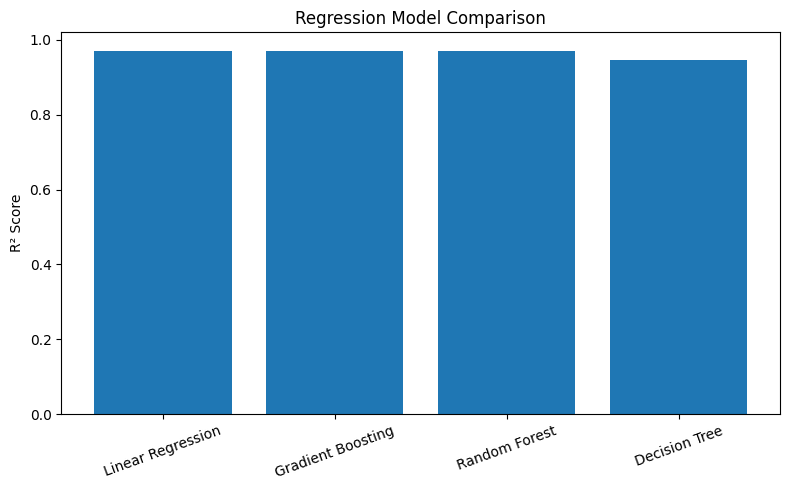

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.bar(

    regression_df["Model"],

    regression_df["R2 Score"]

)

plt.title("Regression Model Comparison")

plt.ylabel("R² Score")

plt.xticks(rotation=20)

plt.tight_layout()

plt.savefig(
    "../reports/figures/regression_model_comparison.png",
    dpi=300
)

plt.show()

### Regression Model Analysis

Four regression algorithms were trained to predict the recommended calorie intake.

Among the evaluated models, Linear Regression achieved the highest R² score (0.9716), followed closely by Gradient Boosting (0.9710) and Random Forest (0.9693). Decision Tree Regression produced comparatively lower performance.

The excellent performance of Linear Regression indicates that the target variable has a strong linear relationship with the predictor variables, particularly the patient's existing caloric intake.

Therefore, Linear Regression was selected as the final regression model for predicting personalized calorie recommendations.

Step 14 – Create Classification Models

In [18]:
classification_models = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        random_state=42
    ),

    "KNN": KNeighborsClassifier(),

    "SVM": SVC(
        random_state=42
    ),

    "Naive Bayes": GaussianNB()

}

Step 15 – Create Evaluation Function

In [19]:
def evaluate_classifier(model, model_name):

    # Train
    model.fit(X_train, y_cls_train)

    # Predict
    predictions = model.predict(X_validation)

    # Metrics
    accuracy = accuracy_score(
        y_cls_validation,
        predictions
    )

    precision = precision_score(
        y_cls_validation,
        predictions,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_cls_validation,
        predictions,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_cls_validation,
        predictions,
        average="weighted",
        zero_division=0
    )

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Model_Object": model
    }

In [20]:
evaluate_classifier

<function __main__.evaluate_classifier(model, model_name)>

In [21]:
classification_results = []

for name, model in classification_models.items():

    print(f"Training {name}...")

    results = evaluate_classifier(model, name)

    classification_results.append(results)

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training KNN...
Training SVM...
Training Naive Bayes...


Step 1 — Create Results DataFrame

In [22]:
classification_df = pd.DataFrame(classification_results)

classification_df

,Model,Accuracy,Precision,Recall,F1 Score,Model_Object
0,Logistic Regression,0.916000,0.915401,0.916000,0.915483,"LogisticRegression(max_iter=1000, random_state..."
1,Decision Tree,1.000000,1.000000,1.000000,1.000000,DecisionTreeClassifier(random_state=42)
2,Random Forest,1.000000,1.000000,1.000000,1.000000,"(DecisionTreeClassifier(max_features='sqrt', r..."
3,KNN,0.717333,0.713942,0.717333,0.711882,KNeighborsClassifier()
4,SVM,0.922667,0.922294,0.922667,0.920976,SVC(random_state=42)
5,Naive Bayes,0.685333,0.873328,0.685333,0.729835,GaussianNB()


Step 2 — Sort the Models

In [23]:
classification_df = classification_df.sort_values(
    by="Accuracy",
    ascending=False
)

classification_df

,Model,Accuracy,Precision,Recall,F1 Score,Model_Object
1,Decision Tree,1.000000,1.000000,1.000000,1.000000,DecisionTreeClassifier(random_state=42)
2,Random Forest,1.000000,1.000000,1.000000,1.000000,"(DecisionTreeClassifier(max_features='sqrt', r..."
4,SVM,0.922667,0.922294,0.922667,0.920976,SVC(random_state=42)
0,Logistic Regression,0.916000,0.915401,0.916000,0.915483,"LogisticRegression(max_iter=1000, random_state..."
3,KNN,0.717333,0.713942,0.717333,0.711882,KNeighborsClassifier()
5,Naive Bayes,0.685333,0.873328,0.685333,0.729835,GaussianNB()


Step 3 — Save Results

In [24]:
classification_df.drop(
    columns=["Model_Object"]
).to_csv(
    "../reports/metrics/classification_results.csv",
    index=False
)

print("Classification Results Saved")

Classification Results Saved


Step 4 — Save Best Model

In [25]:
best_classifier = classification_df.iloc[0]["Model_Object"]

joblib.dump(
    best_classifier,
    "../models/trained/diet_classifier.pkl"
)

print("Best Classifier Saved")

Best Classifier Saved


Step 5 — Create Comparison Graph

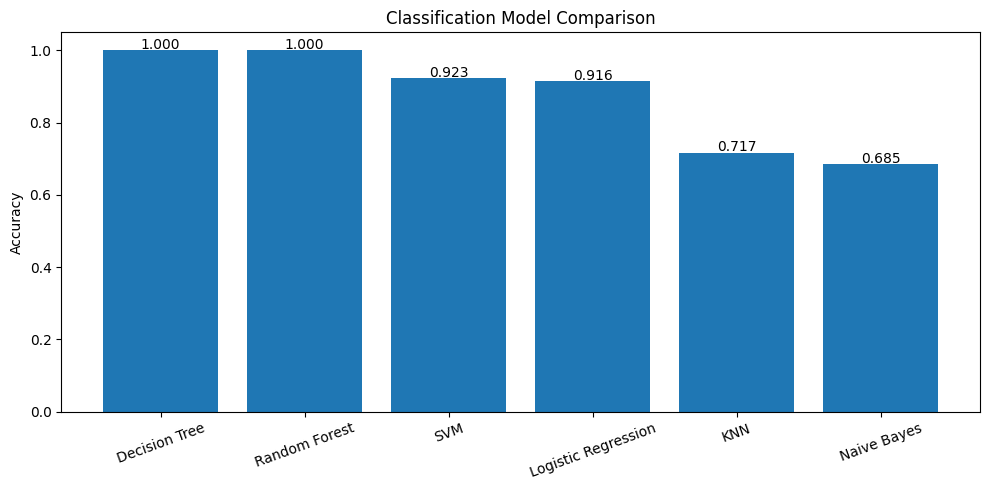

In [26]:
import matplotlib.pyplot as plt

comparison = classification_df.sort_values(
    by="Accuracy",
    ascending=False
)

plt.figure(figsize=(10,5))

bars = plt.bar(
    comparison["Model"],
    comparison["Accuracy"]
)

plt.title("Classification Model Comparison")

plt.ylabel("Accuracy")

plt.xticks(rotation=20)

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height()+0.003,
        f"{bar.get_height():.3f}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    "../reports/figures/classification_model_comparison.png",
    dpi=300
)

plt.show()

Step 6 — Generate Classification Report

In [27]:
from sklearn.metrics import classification_report

In [28]:
best_model = classification_df.iloc[0]["Model_Object"]

predictions = best_model.predict(X_test)

print(
    classification_report(
        y_cls_test,
        predictions
    )
)

                   precision    recall  f1-score   support

    Balanced Diet       1.00      1.00      1.00        60
High-Protein Diet       1.00      1.00      1.00        72
    Low-Carb Diet       1.00      1.00      1.00       350
     Low-Fat Diet       1.00      1.00      1.00       268

         accuracy                           1.00       750
        macro avg       1.00      1.00      1.00       750
     weighted avg       1.00      1.00      1.00       750



Step 7 — Confusion Matrix

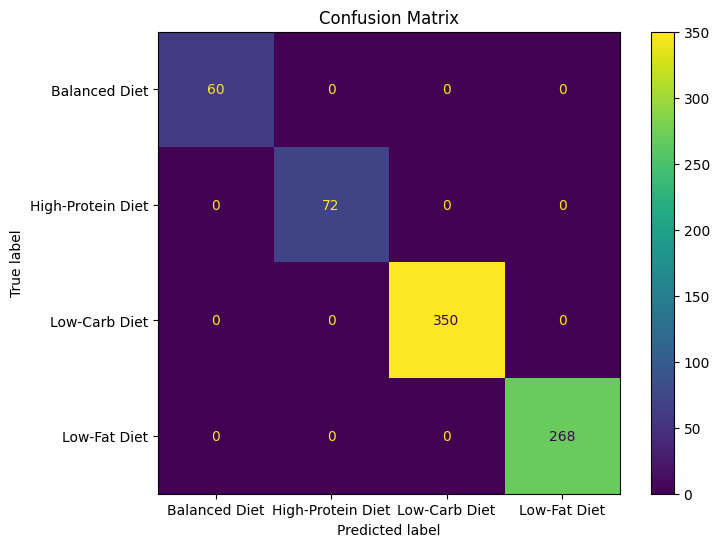

In [29]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

cm = confusion_matrix(
    y_cls_test,
    predictions
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_model.classes_
)

fig, ax = plt.subplots(figsize=(8,6))

disp.plot(ax=ax)

plt.title("Confusion Matrix")

plt.savefig(
    "../reports/figures/confusion_matrix.png",
    dpi=300
)

plt.show()

Step 8 — Save a Complete Comparison File

In [30]:
comparison_df = pd.DataFrame({
    "Task": ["Regression", "Classification"],
    "Best Model": [
        regression_df.iloc[0]["Model"],
        classification_df.iloc[0]["Model"]
    ]
})

comparison_df.to_csv(
    "../reports/metrics/model_comparison.csv",
    index=False
)

comparison_df

,Task,Best Model
0,Regression,Linear Regression
1,Classification,Decision Tree


In [31]:
df = pd.read_csv("../data/processed/cleaned_patient_dataset.csv")

print(df["Recommended_Meal_Plan"].value_counts())

Recommended_Meal_Plan
Low-Carb Diet        2338
Low-Fat Diet         1785
High-Protein Diet     476
Balanced Diet         401
Name: count, dtype: int64


In [32]:
print(df.shape)

df.head()


(5000, 29)


,Age,Gender,Height_cm,Weight_kg,BMI,Chronic_Disease,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Cholesterol_Level,Blood_Sugar_Level,...,Protein_Intake,Carbohydrate_Intake,Fat_Intake,Preferred_Cuisine,Food_Aversions,Recommended_Calories,Recommended_Protein,Recommended_Carbs,Recommended_Fats,Recommended_Meal_Plan
0,56,Other,163,66,24.84,No Disease,175,75,219,124,...,105,179,143,Western,NaN,2150,108,139,145,High-Protein Diet
1,69,Female,171,114,38.99,No Disease,155,72,208,72,...,69,315,75,Mediterranean,NaN,1527,74,266,80,Low-Carb Diet
2,46,Female,172,119,40.22,No Disease,137,101,171,145,...,183,103,148,Western,Sweet,2359,180,145,143,Low-Carb Diet
3,32,Female,197,118,30.41,No Disease,148,91,258,235,...,135,371,120,Western,NaN,2858,137,378,135,Low-Carb Diet
4,60,Female,156,109,44.79,Hypertension,160,109,260,248,...,167,298,48,Indian,Spicy,1937,166,317,56,Low-Carb Diet
